# Extended Data Fig. 9 (revised): hole-side superconductor, three contact pairs

Full critical-current map, file 465 (B 0–14 mT, I_dc ±30 nA). This replaces the file-467 quadrant built by `ed-fig-holesc-frauns.ipynb`, which was the version in the original submission. Output: `figs/vb_fraun_465_contacts.pdf`.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("../utils"))  # repo utils/ (vendored sweep + shared helpers)
from fft_sup_imports import *
%matplotlib inline
update_rc_params('paper')

{'sr830_1': '29-28', 'sr830_2': '28-25', 'sr830_3': '25-24', 'sr830_4': 'I_{6-22}', 'sr830_5': '13-14', 'sr830_6': '10-11', 'sr830_7': '11-13', 'sr830_8': '11-25', 'sr830_9': '13-24'}


['/home/aaron/Fermiology-and-the-cCSC/figs/vb_fraun_465_contacts.pdf',
 '/home/aaron/Fermiology-and-the-cCSC/figs/vb_fraun_465_contacts.png']

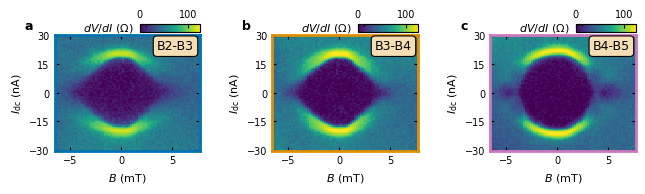

In [2]:
# File 465: the full hole-SC (valence-band) critical-current diamond, same three
# contact pairs and same style as ED9 (which uses file 467 = the 6-13 mT, I_dc>0
# quadrant of this map). B on x, I_dc on y (xs*10 -> nA), viridis SymLogNorm,
# per-panel horizontal colorbar top-right, bold letters, contact-coloured spines.
from matplotlib.gridspec import GridSpec

file = 465
inds = [1, 2, 3]                                  # sr830_1/2/3 = 29-28, 28-25, 25-24
contact_labels = ["B2-B3", "B3-B4", "B4-B5"]
contact_colors = ["#0173B2", "#DE8F05", "#CC78BC"]
letters = ["a", "b", "c"]

data = sl.pload(file_path, file)
print(data['measurement_config'])
B = data['ys'] * 1e3        # mT
Idc = data['xs'] * 10       # nA
I = data['sr830_4_X']

cb_width, cb_height_inches = 0.08, 0.08
fig = plt.figure(figsize=(7.5, 1.5))
gs = GridSpec(1, 3, figure=fig, wspace=0.5)
cb_height_frac = cb_height_inches / fig.get_size_inches()[1]
norm = colors.SymLogNorm(linthresh=70, vmin=0, vmax=200)

for k, ind in enumerate(inds):
    ax = fig.add_subplot(gs[0, k])
    R = data[f'sr830_{ind}_X'] / I
    pm = ax.pcolormesh(B-6.4, Idc, R.T, norm=norm, cmap='viridis', rasterized=True, lw=0)
    ax.set_xlabel(r"$B$ (mT)")
    if k == 0:
        ax.set_ylabel(r"$I_{\mathrm{dc}}$ (nA)")
    else:
        ax.set_ylabel(r"$I_{\mathrm{dc}}$ (nA)")
        # ax.set_yticklabels([])
    ax.yaxis.set_major_locator(plt.MaxNLocator(5))

    fig.canvas.draw()
    pos = ax.get_position()
    fig.text(pos.x0 - 0.04, pos.y1 + 0.04, letters[k], fontweight='bold')
    cax = fig.add_axes([pos.x1 - cb_width, pos.y1 + 0.02, cb_width, cb_height_frac])
    cb = plt.colorbar(pm, cax=cax, ticks=[0, 100], orientation='horizontal')
    cb.ax.set_xticklabels(['0', '100'])
    cb.ax.annotate(r'$dV/dI$ ($\Omega$)', xy=(-0.10, 0.5), xycoords='axes fraction',
                   ha='right', va='center', fontsize=plt.rcParams['axes.labelsize'])
    cb.ax.xaxis.set_ticks_position('top'); cb.ax.xaxis.set_label_position('top')

    for spine in ax.spines.values():
        spine.set_visible(True); spine.set_linewidth(2); spine.set_edgecolor(contact_colors[k])
    ax.text(0.96, 0.96, contact_labels[k], transform=ax.transAxes, ha='right', va='top',
            fontsize=9, color='k',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='wheat', edgecolor='k', linewidth=0.8))

save_fig(fig, "vb_fraun_465_contacts")
